In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# Credit Card Balance Prediction

## Goal
Predict the average credit card balance of a customer from their financial and personal details.

## Problem type
Regression, because the target (Balance) is a number.

## Data
- Source file: Credit_xlsx.csv (400 customers, 10 features and 1 target)
- Target: `Balance`
- Missing values: none


## Understanding the Dataset Columns

The dataset contains 11 columns describing individuals' financial and demographic characteristics, as well as their credit card balance.

| Column | Meaning |
|:---|:---|
| **Income** | Annual income in thousands of dollars |
| **Limit** | Credit card limit |
| **Rating** | Credit rating score |
| **Cards** | Number of credit cards owned |
| **Age** | Age in years |
| **Education** | Number of years of education |
| **Own** | Homeownership status (Yes/No) |
| **Student** | Indicates whether the individual is a student (Yes/No) |
| **Married** | Marital status (Yes/No) |
| **Region** | Geographical region (East, South or West) |
| **Balance** | Target variable representing the average credit card debt |






In [2]:
import pandas as pd

df = pd.read_csv("/kaggle/input/datasets/kefentsemalatji/credit-xlsx/Credit.xlsx.csv", 
                 sep=";"
                 )
print(df.shape)
df.head()

(400, 11)


,Income,Limit,Rating,Cards,Age,Education,Own,Student,Married,Region,Balance
0,14.891,3606,283,2,34,11,No,No,Yes,South,333
1,106.025,6645,483,3,82,15,Yes,Yes,Yes,West,903
2,104.593,7075,514,4,71,11,No,No,No,West,580
3,148.924,9504,681,3,36,11,Yes,No,No,West,964
4,55.882,4897,357,2,68,16,No,No,Yes,South,331


In [3]:
print(df.dtypes)

Income       float64
Limit          int64
Rating         int64
Cards          int64
Age            int64
Education      int64
Own           object
Student       object
Married       object
Region        object
Balance        int64
dtype: object


In [4]:
print(df.isna().sum())

Income       0
Limit        0
Rating       0
Cards        0
Age          0
Education    0
Own          0
Student      0
Married      0
Region       0
Balance      0
dtype: int64


## Exploratory Data Analysis
Which features are linked to a customer's credit card balance?

count     400.0
mean      520.0
std       460.0
min         0.0
25%        69.0
50%       460.0
75%       863.0
max      1999.0
Name: Balance, dtype: float64


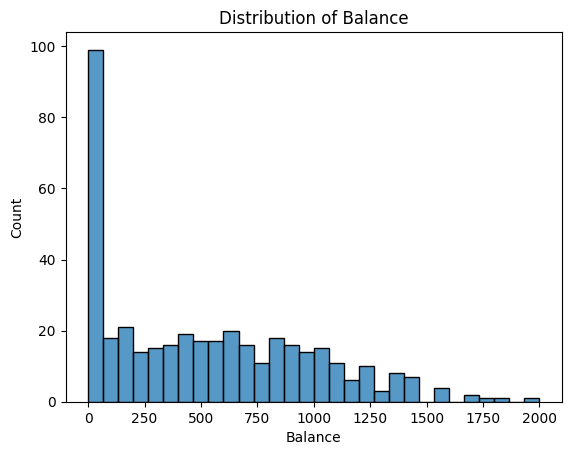

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

print(df["Balance"].describe().round(0))

sns.histplot(df["Balance"], bins=30)
plt.title("Distribution of Balance")
plt.show()

The histogram has a tall bar at 0, which is the 90 customers with no balance. Zero is a real value here, not missing data, but it makes the target lumpy. Keep that in mind.

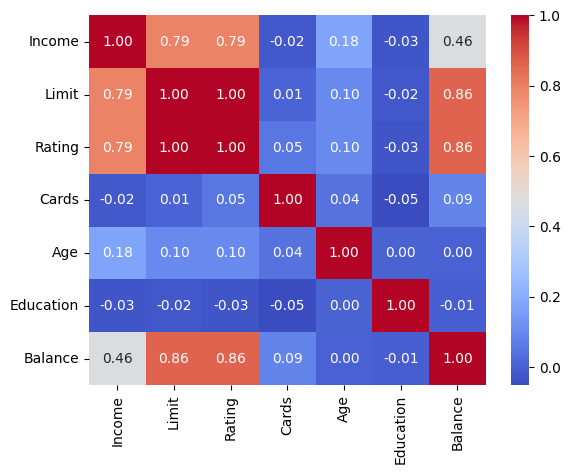

Balance      1.00
Rating       0.86
Limit        0.86
Income       0.46
Cards        0.09
Age          0.00
Education   -0.01
Name: Balance, dtype: float64


In [6]:
corr = df.corr(numeric_only=True)

sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

print(corr["Balance"].sort_values(ascending=False).round(2))

A problem called multicollinearity

Look at the Limit and Rating boxes in the heatmap. Their correlation with each other is about 1.00 (0.997 exactly). They carry almost the same information, because banks set the limit from the rating.

        Limit  Rating
Limit   1.000   0.997
Rating  0.997   1.000


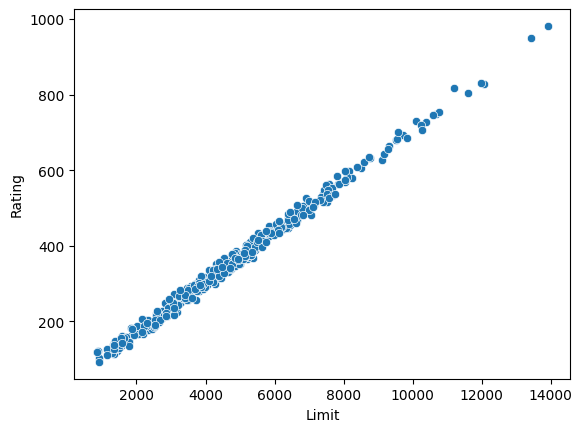

In [7]:
print(df[["Limit", "Rating"]].corr().round(3))

sns.scatterplot(data=df, x="Limit", y="Rating")
plt.show()

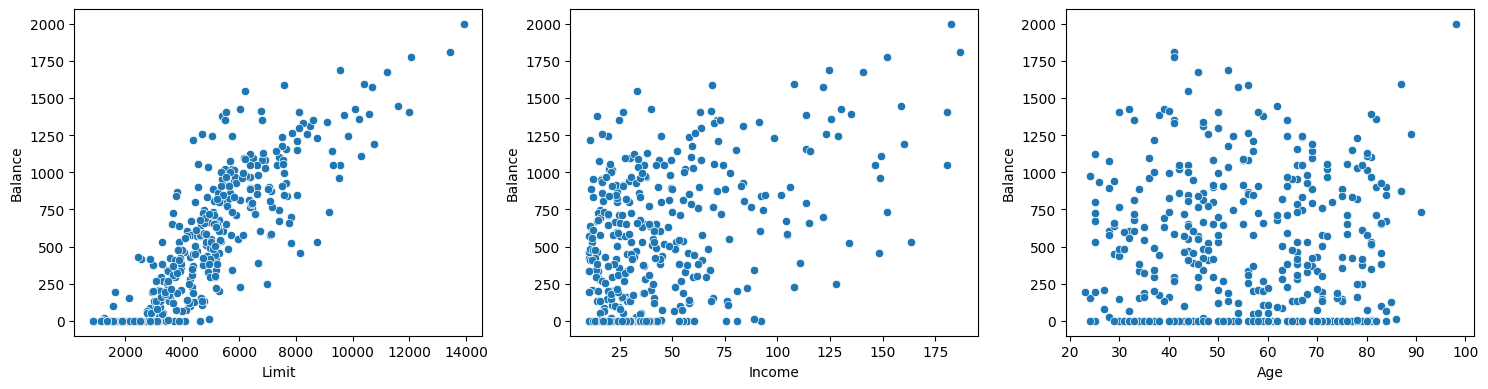

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.scatterplot(data=df, x="Limit", y="Balance", ax=ax[0])
sns.scatterplot(data=df, x="Income", y="Balance", ax=ax[1])
sns.scatterplot(data=df, x="Age", y="Balance", ax=ax[2])
plt.tight_layout()
plt.show()

Student
No     480.0
Yes    877.0
Name: Balance, dtype: float64

Own
No     510.0
Yes    530.0
Name: Balance, dtype: float64

Married
No     523.0
Yes    518.0
Name: Balance, dtype: float64

Region
East     531.0
South    518.0
West     512.0
Name: Balance, dtype: float64



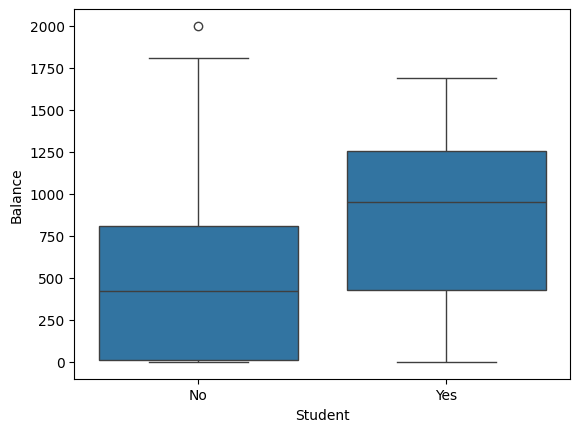

In [9]:
for col in ["Student", "Own", "Married", "Region"]:
    print(df.groupby(col)["Balance"].mean().round(0))
    print()

sns.boxplot(data=df, x="Student", y="Balance")
plt.show()

In [10]:
df["is_zero"] = (df["Balance"] == 0)

print(df.groupby("is_zero")[["Income", "Limit", "Rating"]].mean().round(0))
print(df.groupby("Student")["is_zero"].mean().round(2))

         Income   Limit  Rating
is_zero                        
False      50.0  5485.0   405.0
True       29.0  2153.0   182.0
Student
No     0.25
Yes    0.02
Name: is_zero, dtype: float64


In [11]:
print(df.groupby(pd.qcut(df["Limit"], 4))["is_zero"].mean().round(2))

Limit
(854.999, 3088.0]     0.82
(3088.0, 4622.5]      0.08
(4622.5, 5872.75]     0.00
(5872.75, 13913.0]    0.00
Name: is_zero, dtype: float64


/tmp/ipykernel_50/1218355089.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby(pd.qcut(df["Limit"], 4))["is_zero"].mean().round(2))


## Data Preparation
1. Drop Rating (multicollinearity with Limit)
2. Split into train and test, keeping the share of zero balances equal
3. Build a pipeline: scale the numbers, encode the categories

In [12]:
X = df.drop(columns=["Balance", "Rating", "is_zero"])
y = df["Balance"]

print(X.columns.tolist())

['Income', 'Limit', 'Cards', 'Age', 'Education', 'Own', 'Student', 'Married', 'Region']


### Split into train and test

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=(y == 0)
)

print(X_train.shape, X_test.shape)
print("Zero balances in train:", (y_train == 0).sum())
print("Zero balances in test:", (y_test == 0).sum())

(320, 9) (80, 9)
Zero balances in train: 72
Zero balances in test: 18


### Build the preprocessing pipeline

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_cols = ["Income", "Limit", "Cards", "Age", "Education"]
cat_cols = ["Own", "Student", "Married", "Region"]

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="first"), cat_cols),
])

print(preprocess.fit_transform(X_train).shape)

(320, 10)


## Modelling
Comparing four regression models with 5-fold cross-validation on the training data only.

### Starting with a baseline

A baseline is the dumbest possible model: it predicts the average balance for everyone. Any real model must beat it clearly, or it is not learning anything.


In [15]:
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_validate, KFold

cv = KFold(n_splits=5, shuffle=True, random_state=42)

base_pipe = Pipeline([("prep", preprocess), ("model", DummyRegressor())])

r = cross_validate(
    base_pipe, X_train, y_train, cv=cv,
    scoring=["neg_root_mean_squared_error", "neg_mean_absolute_error", "r2"],
)

print("RMSE:", round(-r["test_neg_root_mean_squared_error"].mean(), 1))
print("MAE:", round(-r["test_neg_mean_absolute_error"].mean(), 1))
print("R2:", round(r["test_r2"].mean(), 3))

RMSE: 467.5
MAE: 398.2
R2: -0.017


### The four models together

In [16]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
import pandas as pd

models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    r = cross_validate(
        pipe, X_train, y_train, cv=cv,
        scoring=["neg_root_mean_squared_error", "neg_mean_absolute_error", "r2"],
    )
    rows.append({
        "Model": name,
        "RMSE": -r["test_neg_root_mean_squared_error"].mean(),
        "RMSE std": r["test_neg_root_mean_squared_error"].std(),
        "MAE": -r["test_neg_mean_absolute_error"].mean(),
        "R2": r["test_r2"].mean(),
    })

results = pd.DataFrame(rows).round(3).sort_values("RMSE")
results

,Model,RMSE,RMSE std,MAE,R2
3,Gradient Boosting,99.979,3.299,65.069,0.953
0,Linear Regression,103.943,13.336,84.491,0.949
1,Ridge,104.372,12.352,85.932,0.949
2,Random Forest,119.265,6.601,72.922,0.933


## Model Comparison

I compared one baseline and four models using 5-fold cross-validation on the training set (320 customers).
The test set was not used in this step.

### Baseline
The baseline predicts the average balance for every customer.
It scored an RMSE of 467.5, an MAE of 398.2 and an R² of -0.017.
This is the score every real model has to beat.


### What I found
- All four models beat the baseline by a large margin (RMSE of about 100 compared with 467).
- Gradient boosting had the best score on every measure.
- The RMSE gap between gradient boosting and linear regression is small (about 4 dollars). The MAE gap is bigger (about 19 dollars).
- Gradient boosting was also the most stable. Its RMSE std (3.3) is much lower than linear regression (13.3), so its score changes less between folds.
- Ridge gave no gain over linear regression. This is expected, because I had already removed Rating, which was almost the same as Limit.
- Random forest had a better MAE than linear regression but a worse RMSE. This means it was usually close but sometimes made large mistakes.

### Decision
I chose gradient boosting as the final model because it was the most accurate and the most stable.
I will keep linear regression as an easy-to-explain benchmark.
I made this choice before looking at the test set.

## Evaluation
Fiting gradient boosting on the full training set and score it once on the 80 hidden customers.

In [17]:
import numpy as np
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

final = Pipeline([
    ("prep", preprocess),
    ("model", GradientBoostingRegressor(random_state=42)),
])
final.fit(X_train, y_train)

pred = final.predict(X_test)

print("RMSE:", round(mean_squared_error(y_test, pred) ** 0.5, 1))
print("MAE:", round(mean_absolute_error(y_test, pred), 1))
print("R2:", round(r2_score(y_test, pred), 3))

RMSE: 70.5
MAE: 52.0
R2: 0.972


### Predicted against actual

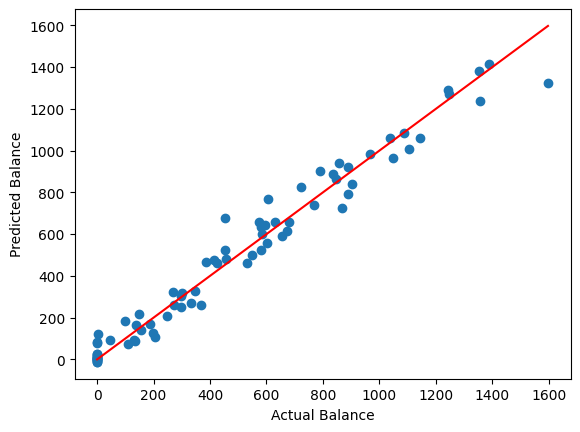

In [18]:
plt.scatter(y_test, pred)
plt.plot([0, y_test.max()], [0, y_test.max()], color="red")
plt.xlabel("Actual Balance")
plt.ylabel("Predicted Balance")
plt.show()

### Check the zero balances and negative predictions

In [19]:
test_results = pd.DataFrame({"actual": y_test, "pred": pred})
test_results["error"] = (test_results["pred"] - test_results["actual"]).abs()

print("Negative predictions:", (pred < 0).sum(), "| lowest:", round(pred.min(), 0))

is_zero = test_results["actual"] == 0
print("MAE for zero-balance customers:", round(test_results.loc[is_zero, "error"].mean(), 1))
print("MAE for all other customers:", round(test_results.loc[~is_zero, "error"].mean(), 1))

Negative predictions: 5 | lowest: -12.0
MAE for zero-balance customers: 18.4
MAE for all other customers: 61.7


In [20]:
pred_clipped = np.clip(pred, 0, None)

### Which features mattered?

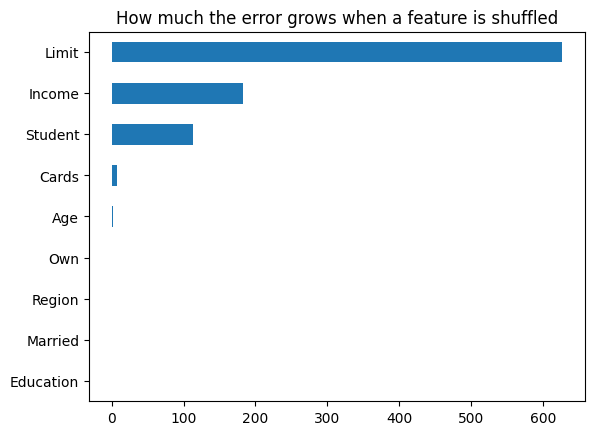

In [21]:
from sklearn.inspection import permutation_importance

pi = permutation_importance(
    final, X_test, y_test, n_repeats=20, random_state=42,
    scoring="neg_root_mean_squared_error",
)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
imp.plot(kind="barh")
plt.title("How much the error grows when a feature is shuffled")
plt.show()

## Final Evaluation

I fitted gradient boosting on the full training set and tested it once on 80 unseen customers.



The model is off by about $52 on average, and it explains about 97% of the differences in balance.
The test score is better than the cross-validation score (RMSE of 100).
With only 80 test customers, the result is a rough estimate, so I treat the two scores as consistent.

### Zero balances
- Mean error for customers with a zero balance: 18.4 (18 customers)
- Mean error for all other customers: 61.7 (62 customers)
- The model made 5 negative predictions, and the lowest was -12 dollars.
  Negative balances are not possible, so in practice I would set them to 0.

The model learned the pattern that low credit limits go with a zero balance.

### Most important features
1. **Limit** (by far the strongest)
2. **Income**
3. **Student**

Cards and Age added very little. Own, Region, Married and Education added nothing.
This agrees with my exploratory analysis.
Limit and Income are correlated, so the model shares the credit between them.
The chart shows what the model relies on, not what causes a higher balance.

### Conclusion
I built a gradient boosting model that predicts the average credit card balance with an average error of about $52 on unseen customers (R² of 0.97).
The balance depends mostly on the credit limit, then income, then whether the customer is a student.
It beat the baseline, linear regression, ridge regression and random forest in cross-validation.

### Limitations
- The dataset is small (400 customers), and the test set has only 80, so the results are only an estimate.
- Gradient boosting is harder to explain than linear regression.
- This is a learning dataset and should not be used for real credit decisions.

## Hyperparameter Tuning
Search for better gradient boosting settings using cross-validation on the training set only.

In [22]:
from sklearn.model_selection import GridSearchCV

gb_pipe = Pipeline([
    ("prep", preprocess),
    ("model", GradientBoostingRegressor(random_state=42)),
])

grid1 = {
    "model__n_estimators": [100, 200, 300],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__max_depth": [2, 3, 4],
}

search1 = GridSearchCV(gb_pipe, grid1, cv=cv, scoring="neg_root_mean_squared_error")
search1.fit(X_train, y_train)

print("Best settings:", search1.best_params_)
print("Best RMSE:", round(-search1.best_score_, 1))

Best settings: {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 300}
Best RMSE: 84.8


In [23]:
grid2 = {
    "model__n_estimators": [300, 500, 800],
    "model__learning_rate": [0.1, 0.2, 0.3],
    "model__max_depth": [1, 2],
}

search2 = GridSearchCV(gb_pipe, grid2, cv=cv, scoring="neg_root_mean_squared_error")
search2.fit(X_train, y_train)

print("Best settings:", search2.best_params_)
print("Best RMSE:", round(-search2.best_score_, 1))

results = pd.DataFrame(search2.cv_results_)
results["RMSE"] = -results["mean_test_score"]
results[["param_model__n_estimators", "param_model__learning_rate",
         "param_model__max_depth", "RMSE", "std_test_score"]].sort_values("RMSE").head(6).round(1)

Best settings: {'model__learning_rate': 0.3, 'model__max_depth': 2, 'model__n_estimators': 800}
Best RMSE: 74.7


,param_model__n_estimators,param_model__learning_rate,param_model__max_depth,RMSE,std_test_score
17,800,0.3,2,74.7,3.1
16,500,0.3,2,75.0,3.0
15,300,0.3,2,75.8,2.8
5,800,0.1,2,79.3,5.4
11,800,0.2,2,81.3,9.9
4,500,0.1,2,81.4,5.2


In [24]:
best_model = search2.best_estimator_
pred = best_model.predict(X_test)

print("RMSE:", round(mean_squared_error(y_test, pred) ** 0.5, 1))
print("MAE:", round(mean_absolute_error(y_test, pred), 1))
print("R2:", round(r2_score(y_test, pred), 3))
print("Negative predictions:", (pred < 0).sum(), "| lowest:", round(pred.min(), 0))

pred_clipped = np.clip(pred, 0, None)
print("RMSE after clipping at 0:", round(mean_squared_error(y_test, pred_clipped) ** 0.5, 1))

RMSE: 57.1
MAE: 41.3
R2: 0.982
Negative predictions: 8 | lowest: -40.0
RMSE after clipping at 0: 56.8


In [25]:
import joblib
joblib.dump(best_model, "credit_balance_model.joblib")

['credit_balance_model.joblib']